# PBMC3k — validated reference analysis

This notebook is a **validated, reproducible version** of `scrna-seq.ipynb` (the original, which is kept unchanged).
It is the scientific reference that the Orditus app is tested against.

**What changed compared with the original, and why**

| Original | Validated | Why |
|---|---|---|
| Cells were executed out of order (regress/scale ran *after* neighbors/Leiden) | Must run top-to-bottom from a clean kernel | Saved results must follow from the code as written |
| PCA computed implicitly inside `neighbors` | Explicit `sc.pp.pca(n_comps=40)` | Same computation, but visible and recorded |
| Many Scanpy defaults implicit (`use_raw`, Leiden `flavor`, seeds) | Written out explicitly | Defaults can change between Scanpy versions |
| Cell types hard-coded by cluster number | Proposed from marker-gene evidence, with checks | Cluster numbering is not stable across versions/seeds |
| No version record | Package versions, seed and parameters recorded and exported | Reproducibility |

All analysis parameters (thresholds, HVG cut-offs, number of PCs, neighbours, Leiden resolution, test method) are **the same as in the original**.

**How to run** (from the project folder, `scrna` environment):

```
conda activate scrna
jupyter nbconvert --to notebook --execute --inplace reference/scrna-seq-validated.ipynb
```

The final section writes `validation/expected/reference_results.h5ad` and `reference_summary.json`.
Never edit those files by hand; re-run this notebook instead.

## 1. Setup: parameters, random seed and package versions

All parameters live in one dictionary, `PARAMS`, so they can be recorded and exported.
One seed (`SEED = 0`, the Scanpy default the original also used implicitly) is passed to every step that uses randomness:
PCA, the neighbour graph, Leiden and UMAP.

In [1]:
import json
import os
import platform
import sys
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")

# The project folder is the first parent folder that contains the raw data file.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "pbmc3k.h5ad").exists()
)

In [2]:
SEED = 0

PARAMS = {
    "load": {"file": "data/pbmc3k.h5ad"},
    "qc": {"mito_prefix": "MT-", "qc_vars": ["mt"], "percent_top": None, "log1p": False},
    "filter": {
        "min_genes": 200,             # sc.pp.filter_cells
        "min_cells": 3,               # sc.pp.filter_genes
        "max_n_genes_by_counts": 2500,  # keep cells with n_genes_by_counts < 2500
        "max_pct_counts_mt": 6.0,       # keep cells with pct_counts_mt < 6
    },
    "normalize": {"target_sum": 1e4},
    "hvg": {"flavor": "seurat", "min_mean": 0.0125, "max_mean": 3, "min_disp": 0.5},
    "regress_out": {"enabled": True, "keys": ["total_counts", "pct_counts_mt"]},
    "scale": {"max_value": 10},
    "pca": {"n_comps": 40, "random_state": SEED},
    "neighbors": {"n_neighbors": 10, "n_pcs": 40, "use_rep": "X_pca", "random_state": SEED},
    "leiden": {"flavor": "leidenalg", "resolution": 1.0, "n_iterations": -1,
               "random_state": SEED, "key_added": "leiden"},
    "umap": {"random_state": SEED},
    "markers": {"groupby": "leiden", "method": "wilcoxon", "use_raw": True, "pts": True},
}

In [3]:
PACKAGES = ["scanpy", "anndata", "numpy", "scipy", "pandas", "scikit-learn", "statsmodels",
            "umap-learn", "pynndescent", "leidenalg", "igraph", "h5py", "matplotlib"]
VERSIONS = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "machine": platform.machine(),
    **{pkg: version(pkg) for pkg in PACKAGES},
}
print("Python executable:", sys.executable)
pd.Series(VERSIONS, name="version").to_frame()

Python executable: /opt/anaconda3/envs/scrna/bin/python


,version
python,3.11.17
platform,macOS-26.5.2-arm64-arm-64bit
machine,arm64
scanpy,1.11.5
anndata,0.12.19
numpy,2.4.6
scipy,1.17.1
pandas,2.3.3
scikit-learn,1.9.1
statsmodels,0.15.0


**Values from the original notebook.** The original only saved a few printed outputs and figures.
They are written down here so this notebook can check itself against them.
The marker genes were read by eye from the original `rank_genes_groups` figure (top 10 per cluster),
so the order of nearly tied genes may be slightly imprecise.

In [4]:
ORIGINAL = {
    "n_mito_genes": 13,
    "filtered_shape": (2670, 13714),
    "n_clusters": 8,
    # adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe(), as printed
    "qc_describe": pd.DataFrame(
        {
            "n_genes_by_counts": [2700, 846.994074, 282.104964, 212, 690, 817, 953.25, 3422],
            "total_counts": [2700, 2366.900391, 1094.262085, 548, 1757.75, 2197, 2763, 15844],
            "pct_counts_mt": [2700, 2.215132, 1.165438, 0, 1.536238, 2.029639, 2.640218, 22.569027],
        },
        index=["count", "mean", "std", "min", "25%", "50%", "75%", "max"],
    ),
    # Original cluster -> label, and top 10 marker genes from the original figure.
    "labels": {
        "0": "CD4+ T cells", "1": "CD14+ Monocytes", "2": "B cells", "3": "CD8+ T cells",
        "4": "FCGR3A+ Monocytes", "5": "NK cells", "6": "Dendritic cells", "7": "Megakaryocytes",
    },
    "top10_markers": {
        "0": ["RPS12", "LDHB", "RPS25", "RPS27", "RPS6", "RPS3", "RPS14", "TPT1", "CD3D", "RPL31"],
        "1": ["S100A9", "LYZ", "S100A8", "TYROBP", "FCN1", "FTL", "CST3", "S100A6", "LGALS2", "LGALS1"],
        "2": ["CD74", "CD79A", "HLA-DRA", "CD79B", "HLA-DPB1", "MS4A1", "HLA-DQA1", "CD37", "HLA-DRB1", "HLA-DQB1"],
        "3": ["CCL5", "NKG7", "CST7", "B2M", "GZMA", "HLA-C", "IL32", "CTSW", "HLA-A", "GZMK"],
        "4": ["LST1", "COTL1", "AIF1", "FCER1G", "FTH1", "IFITM3", "SAT1", "FTL", "PSAP", "CTSS"],
        "5": ["NKG7", "GNLY", "GZMB", "CTSW", "PRF1", "GZMA", "CST7", "HLA-C", "B2M", "FGFBP2"],
        "6": ["HLA-DPA1", "HLA-DPB1", "HLA-DRA", "HLA-DRB1", "CD74", "HLA-DQA1", "CST3", "FCER1A", "HLA-DRB5", "HLA-DMA"],
        "7": ["SDPR", "GNG11", "PF4", "PPBP", "NRGN", "GPX1", "SPARC", "TPM4", "RGS18", "CALM3"],
    },
}

## 2. Load the raw PBMC3k data

The original called `sc.datasets.pbmc3k()`, which downloads the file (or reuses a cached copy that depends on the
current folder). Here we read the saved copy `data/pbmc3k.h5ad` instead; it was checked to contain exactly
the same counts, cell barcodes and gene names.

We also check that the input really is **raw counts** (non-negative whole numbers), because every later step assumes it.

In [5]:
adata = sc.read_h5ad(PROJECT_ROOT / PARAMS["load"]["file"])
adata.var_names_make_unique()

counts = adata.X.data
assert adata.shape == (2700, 32738), adata.shape
assert counts.min() >= 0 and np.all(counts == np.round(counts)), "X is not raw integer counts"
assert adata.obs_names.is_unique and adata.var_names.is_unique
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

## 3. Quality-control metrics

Mitochondrial genes are identified by the `MT-` prefix (human gene symbols). A high fraction of mitochondrial
reads usually indicates a damaged or dying cell. `calculate_qc_metrics` adds, per cell, the number of detected
genes (`n_genes_by_counts`), total counts (`total_counts`) and the percentage of counts from mitochondrial genes
(`pct_counts_mt`). Parameters are identical to the original.

In [6]:
adata.var["mt"] = adata.var_names.str.startswith(PARAMS["qc"]["mito_prefix"])
n_mito = int(adata.var["mt"].sum())
print(f"{n_mito} mitochondrial genes:", ", ".join(adata.var_names[adata.var["mt"]]))
assert n_mito == ORIGINAL["n_mito_genes"]

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=PARAMS["qc"]["qc_vars"],
    percent_top=PARAMS["qc"]["percent_top"],
    log1p=PARAMS["qc"]["log1p"],
    inplace=True,
)
qc_describe = adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe()
qc_describe

13 mitochondrial genes: MT-ND1, MT-ND2, MT-CO1, MT-CO2, MT-ATP8, MT-ATP6, MT-CO3, MT-ND3, MT-ND4L, MT-ND4, MT-ND5, MT-ND6, MT-CYB


,n_genes_by_counts,total_counts,pct_counts_mt
count,2700.000000,2700.000000,2700.000000
mean,846.994074,2366.900391,2.215132
std,282.104964,1094.262085,1.165438
min,212.000000,548.000000,0.000000
25%,690.000000,1757.750000,1.536238
50%,817.000000,2197.000000,2.029639
75%,953.250000,2763.000000,2.640218
max,3422.000000,15844.000000,22.569027


In [7]:
# The original printed the table to 6 decimals, so compare with a matching tolerance.
qc_max_abs_diff = float((qc_describe - ORIGINAL["qc_describe"]).abs().max().max())
print(f"Largest difference from the original QC table: {qc_max_abs_diff:.2e}")
assert qc_max_abs_diff < 1e-5

Largest difference from the original QC table: 4.75e-07


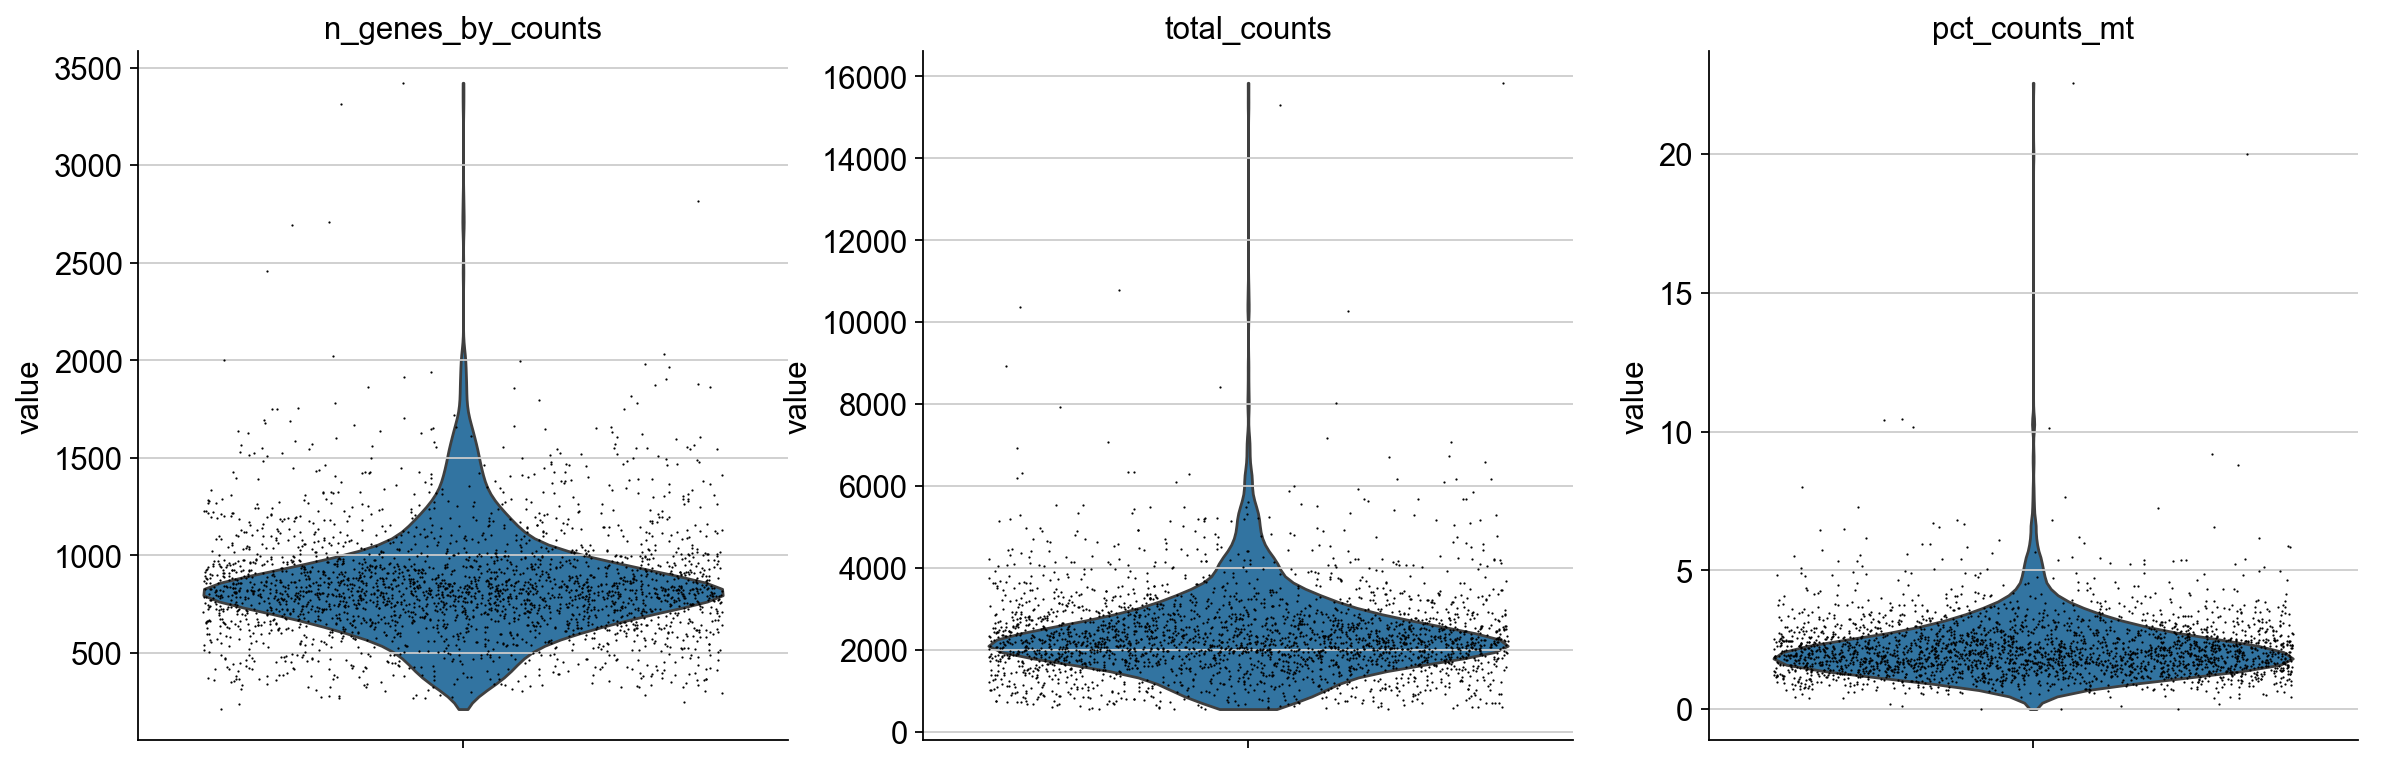

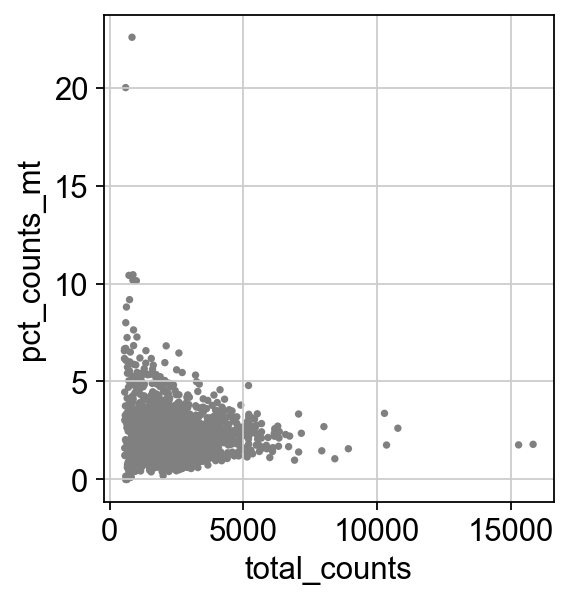

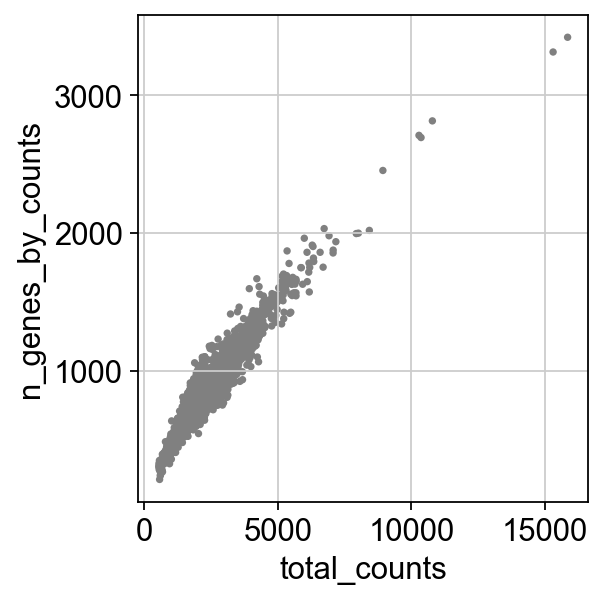

In [8]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], jitter=0.4, multi_panel=True)
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts")

## 4. Filter low-quality cells and rarely detected genes

Same thresholds and order as the original:

1. `filter_cells(min_genes=200)`: remove near-empty droplets.
2. `filter_genes(min_cells=3)`: remove genes detected in fewer than 3 cells.
3. Keep cells with `n_genes_by_counts < 2500`. Unusually many genes is a simple **proxy for doublets**
   (two cells in one droplet). No dedicated doublet-detection method is used.
4. Keep cells with `pct_counts_mt < 6`.

**Note on QC metrics.** Steps 3–4 use the QC metrics calculated in section 3, *before* genes were removed in step 2,
and these same values are later used by `regress_out`. This is the convention of the Scanpy tutorial and of
the original analysis, so it is kept. The next cell shows that recalculating the metrics after gene filtering
would not change which cells pass.

In [9]:
n_cells_before, n_genes_before = adata.shape
sc.pp.filter_cells(adata, min_genes=PARAMS["filter"]["min_genes"])
sc.pp.filter_genes(adata, min_cells=PARAMS["filter"]["min_cells"])

# Diagnostic only (does not change adata): would recomputed metrics change which cells pass?
recomputed = sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=False)[0]
f = PARAMS["filter"]
keep_original = (adata.obs.n_genes_by_counts < f["max_n_genes_by_counts"]) & (adata.obs.pct_counts_mt < f["max_pct_counts_mt"])
keep_recomputed = (recomputed.n_genes_by_counts < f["max_n_genes_by_counts"]) & (recomputed.pct_counts_mt < f["max_pct_counts_mt"])
n_status_changes = int((keep_original != keep_recomputed).sum())
print(f"Cells whose pass/fail status would change with recomputed metrics: {n_status_changes}")

# The original applied the two thresholds one after the other; one combined mask is equivalent.
adata = adata[keep_original, :].copy()
print(f"Cells: {n_cells_before} -> {adata.n_obs}   Genes: {n_genes_before} -> {adata.n_vars}")
assert adata.shape == ORIGINAL["filtered_shape"], adata.shape

Cells whose pass/fail status would change with recomputed metrics: 0
Cells: 2700 -> 2670   Genes: 32738 -> 13714


## 5. Normalise and log-transform

Raw counts are kept in `layers["counts"]` before normalising. Each cell is scaled to 10,000 total counts
(removing differences in sequencing depth), then `log1p` is applied (log(x + 1)), which makes the
variance less dependent on the mean.

In [10]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=PARAMS["normalize"]["target_sum"])
sc.pp.log1p(adata)

## 6. Highly variable genes (HVGs)

Genes that vary much more than expected for their mean expression carry most of the biological signal.
The `seurat` flavor (the default, now written explicitly) expects **log-normalised** data, which is what we have.
Thresholds are the same as the original.

Highly variable genes: 1846 of 13714


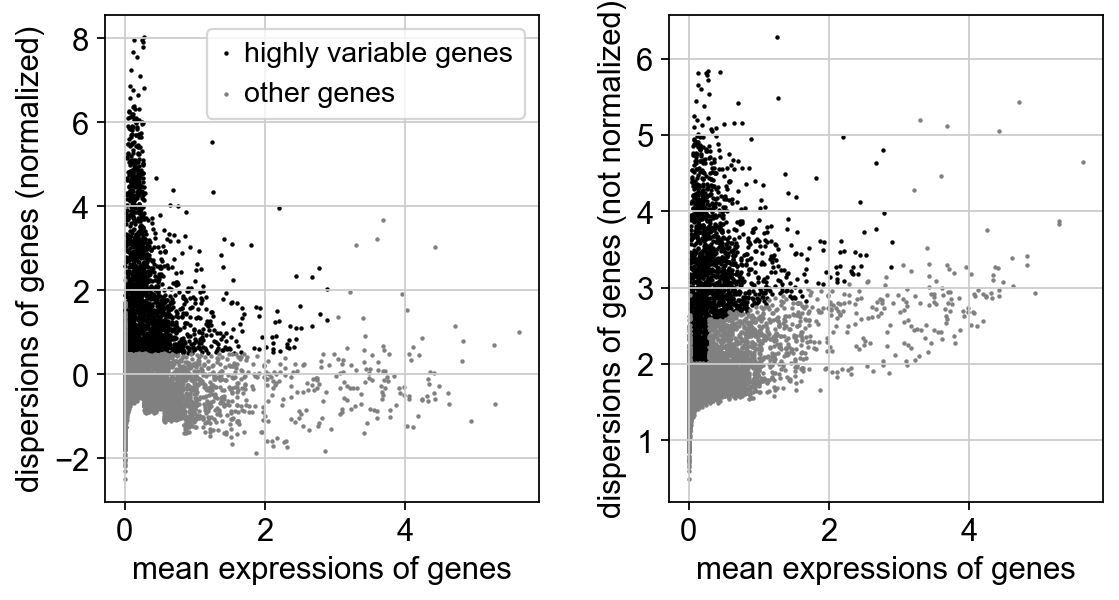

In [11]:
h = PARAMS["hvg"]
sc.pp.highly_variable_genes(adata, flavor=h["flavor"], min_mean=h["min_mean"], max_mean=h["max_mean"], min_disp=h["min_disp"])
n_hvg = int(adata.var["highly_variable"].sum())
print(f"Highly variable genes: {n_hvg} of {adata.n_vars}")
sc.pl.highly_variable_genes(adata)

## 7. Keep full-gene expression in `adata.raw`, then subset to HVGs

`adata.raw` stores the **log-normalised expression of all 13,714 genes**. Marker-gene testing (section 12)
uses it, so markers are not limited to HVGs and are not affected by regression or scaling.
The working matrix is then reduced to the HVGs. `.copy()` makes it a real object instead of a view
(the original modified a view, which Scanpy silently copied).

*Limitation kept from the original:* `layers["counts"]` is reduced to HVGs as well, so full-gene raw counts are not
kept in this object. This does not affect any result in this analysis.

In [12]:
adata.raw = adata
adata = adata[:, adata.var["highly_variable"]].copy()
print(f"adata.raw: {adata.raw.shape}   working matrix: {adata.shape}")
assert adata.raw.shape == ORIGINAL["filtered_shape"]

adata.raw: (2670, 13714)   working matrix: (2670, 1846)


## 8. Optional regression, then scaling

`regress_out` removes the linear effect of total counts and mitochondrial percentage from each gene.
**This is an analysis choice, not a requirement.** It can reduce technical effects, but it can also remove
real biology that correlates with these variables, and many current workflows skip it. It is kept here
(`PARAMS["regress_out"]["enabled"] = True`) because the original analysis used it.

`scale` then gives every gene mean 0 and variance 1, so highly expressed genes don't dominate PCA.
Values are clipped at 10 standard deviations.

In [13]:
if PARAMS["regress_out"]["enabled"]:
    sc.pp.regress_out(adata, PARAMS["regress_out"]["keys"])
sc.pp.scale(adata, max_value=PARAMS["scale"]["max_value"])

/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:666: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:666: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


## 9. Principal component analysis (explicit)

The original never called PCA. `sc.pp.neighbors(n_pcs=40)` computed it silently with **40 components**
(Scanpy calls `pca(n_comps=n_pcs)` in that case; not 50). Here the same computation is an explicit,
recorded step: `sc.pp.pca(n_comps=40)` with otherwise default settings.

Variance explained by 40 PCs: 0.115


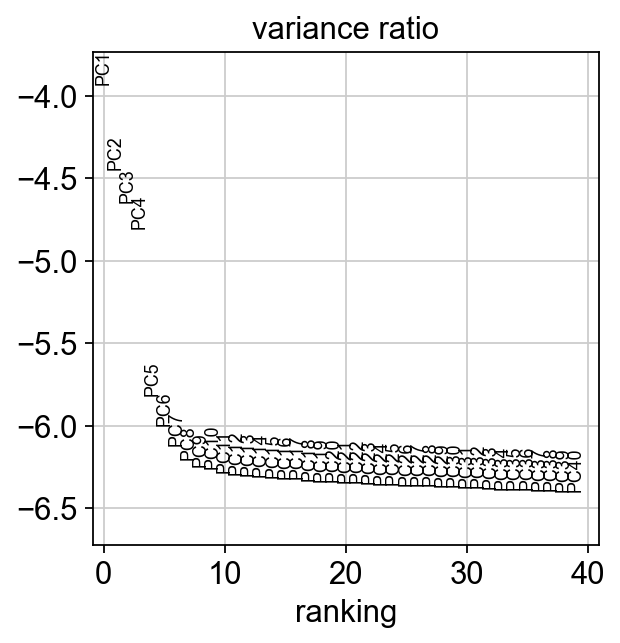

In [14]:
sc.pp.pca(adata, n_comps=PARAMS["pca"]["n_comps"], random_state=PARAMS["pca"]["random_state"])
pca_variance_ratio = adata.uns["pca"]["variance_ratio"]
print(f"Variance explained by 40 PCs: {pca_variance_ratio.sum():.3f}")
sc.pl.pca_variance_ratio(adata, n_pcs=PARAMS["pca"]["n_comps"], log=True)

## 10. Nearest-neighbour graph

Each cell is connected to its 10 most similar cells in the 40-PC space. Clustering and UMAP are both built
on this graph. `use_rep="X_pca"` makes explicit which representation is used. With fewer than 4,096 cells
Scanpy computes exact neighbours, so this step is deterministic.

In [15]:
n = PARAMS["neighbors"]
sc.pp.neighbors(adata, n_neighbors=n["n_neighbors"], n_pcs=n["n_pcs"], use_rep=n["use_rep"], random_state=n["random_state"])

/opt/anaconda3/envs/scrna/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 11. Leiden clustering and UMAP

Leiden settings are the original's defaults, now written explicitly: `flavor="leidenalg"`, `resolution=1.0`,
`n_iterations=-1` (run until stable) and `random_state=0`. Scanpy warns that its default flavor will change to
`igraph` in future. We deliberately **don't** switch, because that is a different implementation and could give
different clusters.

UMAP is a 2-D picture of the neighbour graph for visualisation only. Distances on a UMAP should not be
over-interpreted.

In [16]:
l = PARAMS["leiden"]
sc.tl.leiden(adata, flavor=l["flavor"], resolution=l["resolution"], n_iterations=l["n_iterations"],
             random_state=l["random_state"], key_added=l["key_added"])
sc.tl.umap(adata, random_state=PARAMS["umap"]["random_state"])

cluster_sizes = adata.obs["leiden"].value_counts().sort_index()
print(f"Number of clusters: {len(cluster_sizes)}")
cluster_sizes.rename("n_cells").to_frame().T

/var/folders/07/3l4k_4wn505bhm3d0hvndqqc0000gn/T/ipykernel_60920/222152534.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, flavor=l["flavor"], resolution=l["resolution"], n_iterations=l["n_iterations"],


Number of clusters: 8


leiden,0,1,2,3,4,5,6,7
n_cells,1131,430,342,326,214,178,36,13


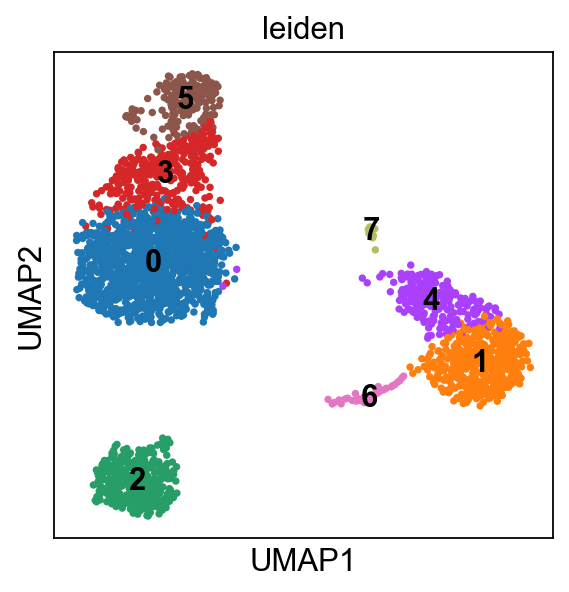

In [17]:
sc.pl.umap(adata, color=["leiden"], legend_loc="on data")

## 12. Marker genes (differential expression)

Each cluster is compared with all other cells using the Wilcoxon rank-sum test on **`adata.raw`**
(log-normalised, all genes), which `use_raw=True` now makes explicit. `pts=True` also records the fraction of cells
expressing each gene.

**Statistical caveat.** The clusters were defined from the same cells being tested, so p-values are strongly
inflated ("double dipping"). Use them to **rank** candidate markers, not as evidence of significance.

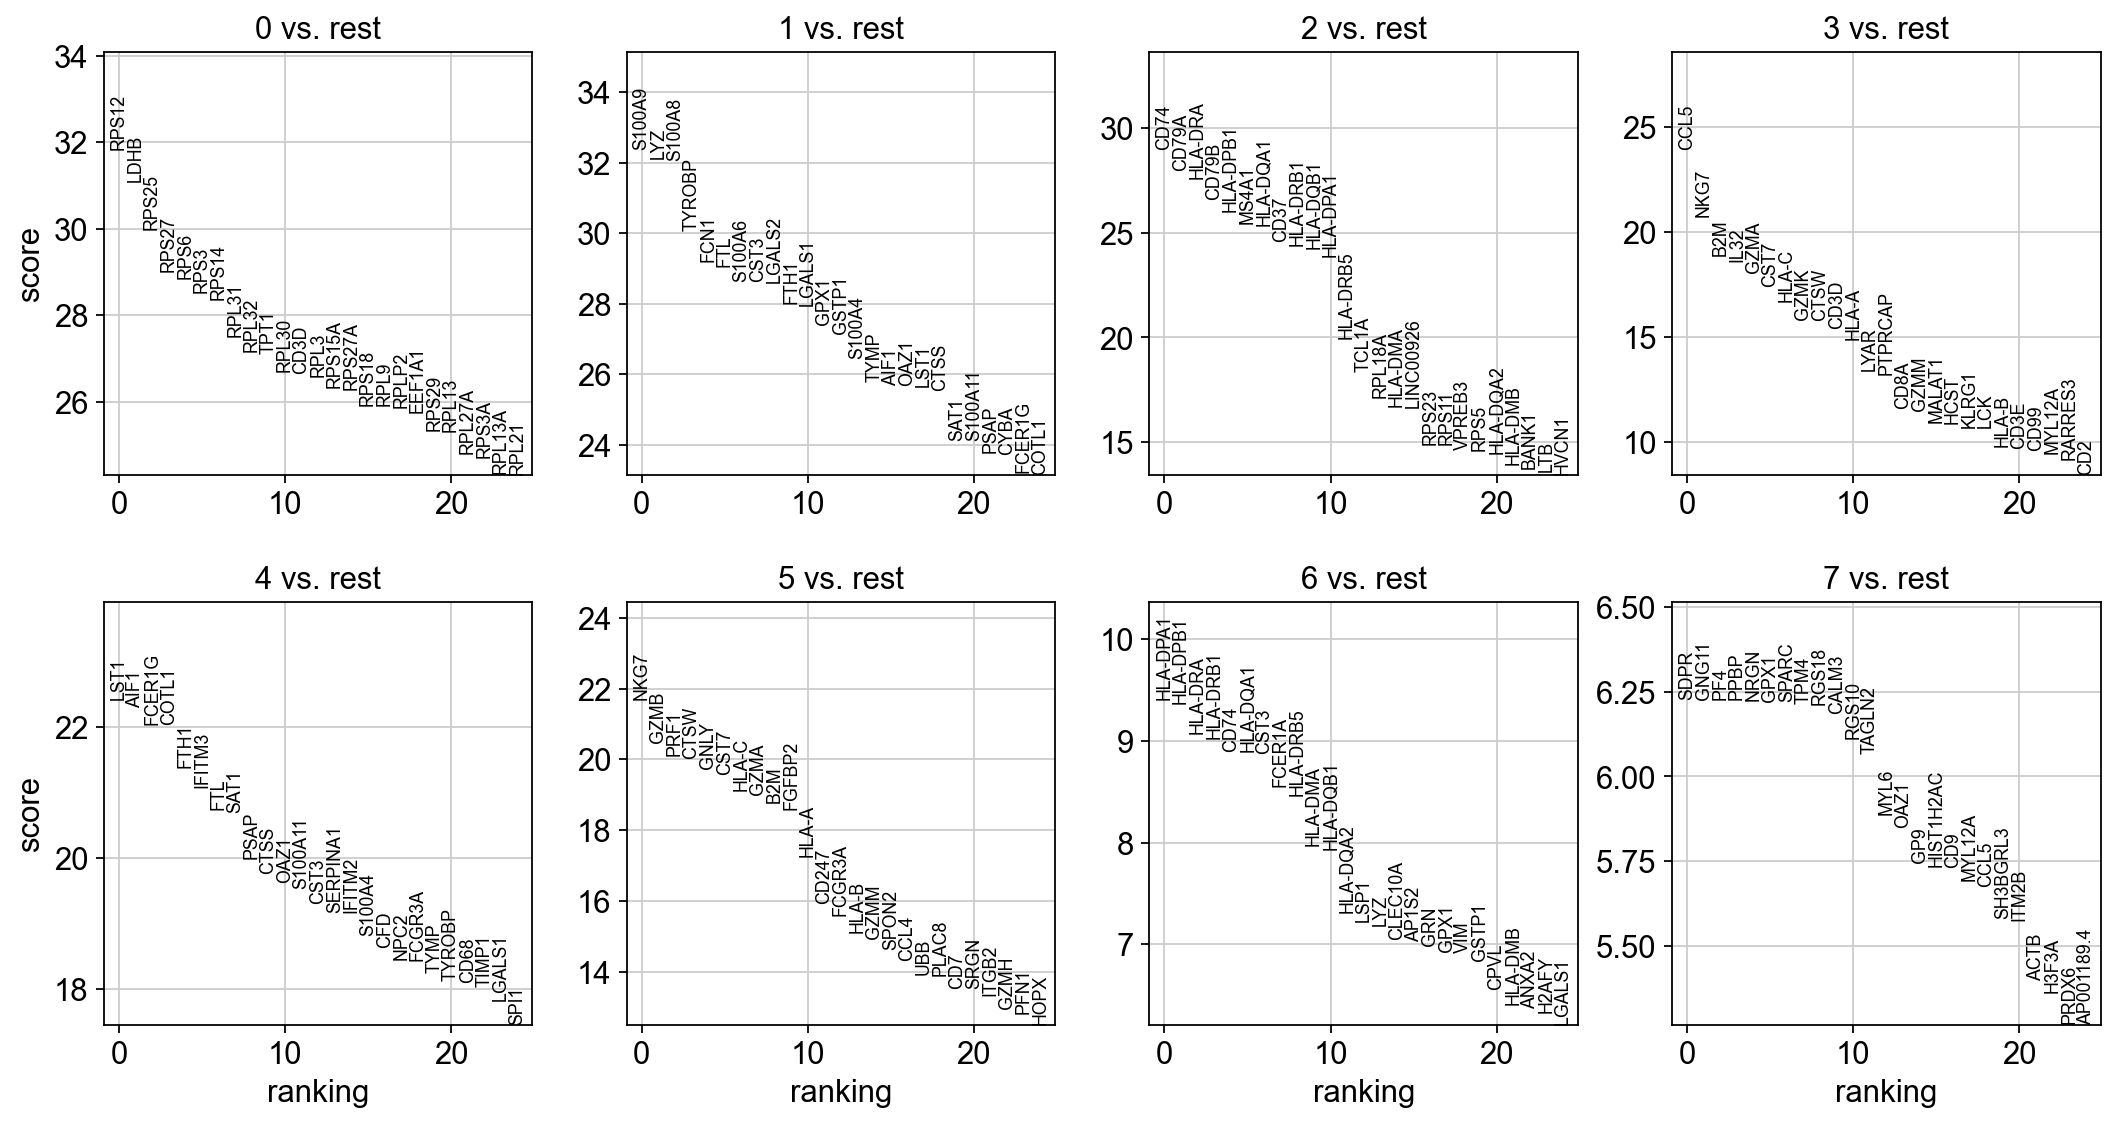

,0,1,2,3,4,5,6,7
0,RPS12,S100A9,CD74,CCL5,LST1,NKG7,HLA-DPA1,SDPR
1,LDHB,LYZ,CD79A,NKG7,AIF1,GZMB,HLA-DPB1,GNG11
2,RPS25,S100A8,HLA-DRA,B2M,FCER1G,PRF1,HLA-DRA,PF4
3,RPS27,TYROBP,CD79B,IL32,COTL1,CTSW,HLA-DRB1,PPBP
4,RPS6,FCN1,HLA-DPB1,GZMA,FTH1,GNLY,CD74,NRGN
5,RPS3,FTL,MS4A1,CST7,IFITM3,CST7,HLA-DQA1,GPX1
6,RPS14,S100A6,HLA-DQA1,HLA-C,FTL,HLA-C,CST3,SPARC
7,RPL31,CST3,CD37,GZMK,SAT1,GZMA,FCER1A,TPM4
8,RPL32,LGALS2,HLA-DRB1,CTSW,PSAP,B2M,HLA-DRB5,RGS18
9,TPT1,FTH1,HLA-DQB1,CD3D,CTSS,FGFBP2,HLA-DMA,CALM3


In [18]:
m = PARAMS["markers"]
sc.tl.rank_genes_groups(adata, m["groupby"], method=m["method"], use_raw=m["use_raw"], pts=m["pts"])
sc.pl.rank_genes_groups(adata, n_genes=25, sharey=False)

ranked_names = pd.DataFrame(adata.uns["rank_genes_groups"]["names"])  # columns = clusters, rows = rank
ranked_names.head(10)

## 13. Cell-type annotation from marker-gene evidence

The original assigned names to cluster **numbers** (`'0' -> 'CD4+ T cells'`, ...). That breaks as soon as Leiden numbers
the clusters differently. Here labels are **proposed from marker-gene evidence**:

1. Use canonical markers for each expected PBMC cell type (below).
2. For each cluster, compute the mean log-normalised expression of each marker (`adata.raw`), z-score it across
   clusters, and average the z-scores within each marker set. The proposed label is the set with the highest score.
3. A cluster is flagged **ambiguous** if the best and second-best scores differ by less than 0.5.
4. Checks: the proposed label's markers must be supported by differential expression (at least one marker
   in that cluster's top 50 ranked genes), and all eight expected cell types must be found.

If a check fails, the notebook stops so the evidence can be reviewed. Parameters are not tuned to make it pass.
Labels are stored in `obs["cell_type"]`, separate from the computed `obs["leiden"]`.
They are a **biological interpretation** and should be reviewed by the analyst using the evidence table and dot plot.

In [19]:
MARKER_SETS = {
    "CD4+ T cells": ["IL7R", "CCR7"],
    "CD8+ T cells": ["CD8A", "CD8B"],
    "NK cells": ["GNLY", "NKG7"],
    "B cells": ["MS4A1", "CD79A"],
    "CD14+ Monocytes": ["CD14", "LYZ"],
    "FCGR3A+ Monocytes": ["FCGR3A", "MS4A7"],
    "Dendritic cells": ["FCER1A", "CST3"],
    "Megakaryocytes": ["PPBP"],
}
CONTEXT_MARKERS = ["CD3D"]  # shown for context (T cells), not used for scoring
AMBIGUITY_MARGIN = 0.5
MAX_DE_RANK = 50

marker_genes = [g for genes in MARKER_SETS.values() for g in genes]
expr = sc.get.obs_df(adata, keys=marker_genes + CONTEXT_MARKERS, use_raw=True)
mean_expr = expr.groupby(adata.obs["leiden"], observed=True).mean()
z = (mean_expr - mean_expr.mean()) / mean_expr.std(ddof=0)
set_scores = pd.DataFrame({ct: z[genes].mean(axis=1) for ct, genes in MARKER_SETS.items()})
set_scores.round(2)

,CD4+ T cells,CD8+ T cells,NK cells,B cells,CD14+ Monocytes,FCGR3A+ Monocytes,Dendritic cells,Megakaryocytes
leiden,,,,,,,,
0,2.19,0.36,-0.51,-0.37,-0.64,-0.64,-0.66,-0.39
1,-0.63,-0.64,-0.48,-0.39,2.11,-0.16,0.39,-0.36
2,-0.00,-0.62,-0.55,2.64,-0.68,-0.58,-0.66,-0.39
3,0.59,2.46,0.56,-0.40,-0.66,-0.49,-0.66,-0.39
4,-0.61,-0.53,-0.40,-0.36,0.44,2.19,0.39,-0.32
5,-0.49,0.01,2.41,-0.39,-0.68,0.48,-0.61,-0.40
6,-0.31,-0.55,-0.42,-0.27,0.70,-0.32,2.02,-0.39
7,-0.73,-0.48,-0.60,-0.45,-0.59,-0.48,-0.20,2.64


In [20]:
def de_rank(cluster: str, gene: str) -> int | None:
    """1-based rank of `gene` in the cluster's marker list (None if not ranked)."""
    hits = np.flatnonzero(ranked_names[cluster].to_numpy() == gene)
    return int(hits[0]) + 1 if len(hits) else None


rows = []
for cluster, scores in set_scores.iterrows():
    best, second = scores.sort_values(ascending=False).index[:2]
    ranks = {g: de_rank(cluster, g) for g in MARKER_SETS[best]}
    best_rank = min(r for r in ranks.values() if r is not None) if any(ranks.values()) else None
    rows.append({
        "cluster": cluster,
        "n_cells": int(cluster_sizes[cluster]),
        "proposed_label": best,
        "score": round(float(scores[best]), 3),
        "second_label": second,
        "margin": round(float(scores[best] - scores[second]), 3),
        "ambiguous": bool(scores[best] - scores[second] < AMBIGUITY_MARGIN),
        "marker_DE_ranks": ", ".join(f"{g}:{r}" for g, r in ranks.items()),
        "best_marker_DE_rank": best_rank,
        "top5_DE_genes": ", ".join(ranked_names[cluster].head(5)),
    })
evidence = pd.DataFrame(rows).set_index("cluster")
evidence

,n_cells,proposed_label,score,second_label,margin,ambiguous,marker_DE_ranks,best_marker_DE_rank,top5_DE_genes
cluster,,,,,,,,,
0,1131,CD4+ T cells,2.190,CD8+ T cells,1.833,False,"IL7R:43, CCR7:87",43,"RPS12, LDHB, RPS25, RPS27, RPS6"
1,430,CD14+ Monocytes,2.110,Dendritic cells,1.723,False,"CD14:30, LYZ:2",2,"S100A9, LYZ, S100A8, TYROBP, FCN1"
2,342,B cells,2.641,CD4+ T cells,2.643,False,"MS4A1:6, CD79A:2",2,"CD74, CD79A, HLA-DRA, CD79B, HLA-DPB1"
3,326,CD8+ T cells,2.457,CD4+ T cells,1.868,False,"CD8A:14, CD8B:31",14,"CCL5, NKG7, B2M, IL32, GZMA"
4,214,FCGR3A+ Monocytes,2.192,CD14+ Monocytes,1.757,False,"FCGR3A:19, MS4A7:37",19,"LST1, AIF1, FCER1G, COTL1, FTH1"
5,178,NK cells,2.407,FCGR3A+ Monocytes,1.931,False,"GNLY:5, NKG7:1",1,"NKG7, GZMB, PRF1, CTSW, GNLY"
6,36,Dendritic cells,2.015,CD14+ Monocytes,1.318,False,"FCER1A:8, CST3:7",7,"HLA-DPA1, HLA-DPB1, HLA-DRA, HLA-DRB1, CD74"
7,13,Megakaryocytes,2.645,Dendritic cells,2.842,False,PPBP:4,4,"SDPR, GNG11, PF4, PPBP, NRGN"


In [21]:
unsupported = evidence.index[evidence["best_marker_DE_rank"].isna() | (evidence["best_marker_DE_rank"] > MAX_DE_RANK)].tolist()
missing_types = sorted(set(MARKER_SETS) - set(evidence["proposed_label"]))
print("Ambiguous clusters:", evidence.index[evidence["ambiguous"]].tolist() or "none")
print("Clusters sharing a label:", evidence["proposed_label"][evidence["proposed_label"].duplicated(keep=False)].to_dict() or "none")
assert not unsupported, f"Proposed labels not supported by DE (no marker in top {MAX_DE_RANK}) for clusters {unsupported}"
assert not missing_types, f"Expected cell types not found: {missing_types}"

adata.obs["cell_type"] = adata.obs["leiden"].map(evidence["proposed_label"]).astype("category")
adata.obs["cell_type"].value_counts().rename("n_cells").to_frame()

Ambiguous clusters: none
Clusters sharing a label: none


,n_cells
cell_type,
CD4+ T cells,1131
CD14+ Monocytes,430
B cells,342
CD8+ T cells,326
FCGR3A+ Monocytes,214
NK cells,178
Dendritic cells,36
Megakaryocytes,13


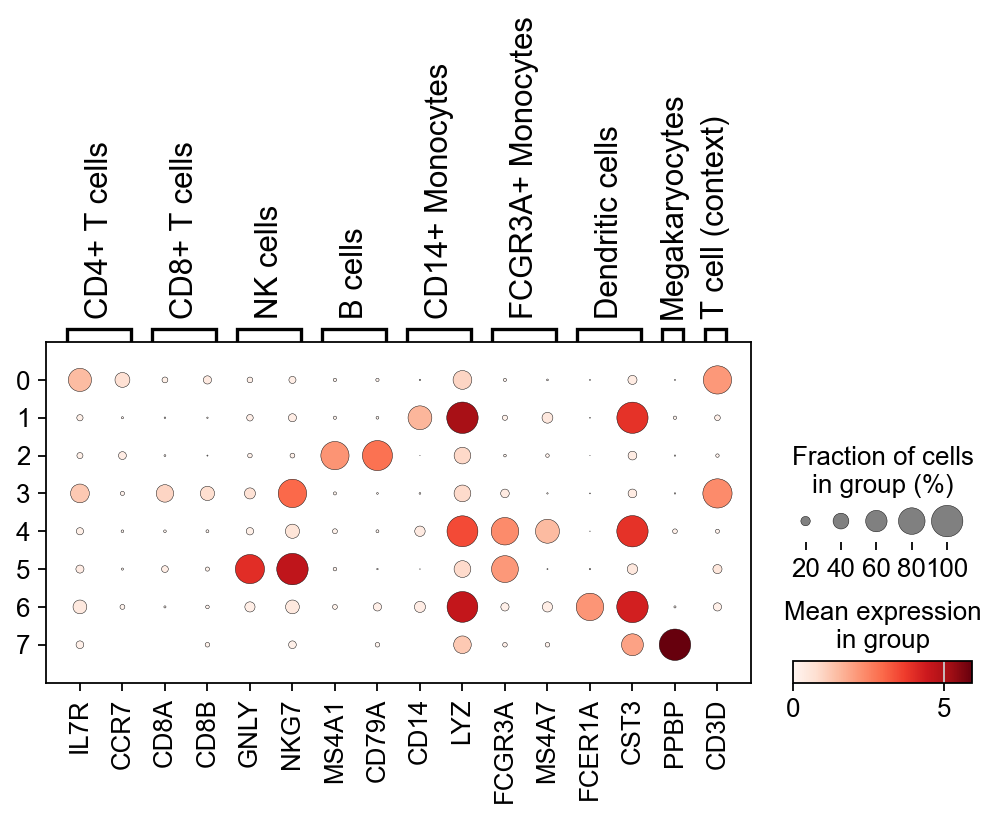

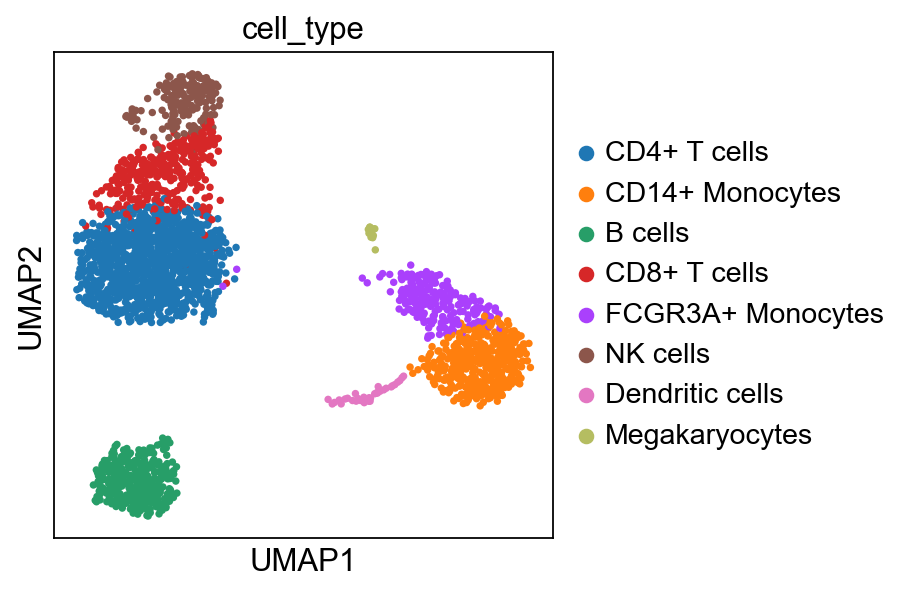

In [22]:
sc.pl.dotplot(adata, MARKER_SETS | {"T cell (context)": CONTEXT_MARKERS}, groupby="leiden", use_raw=True)
sc.pl.umap(adata, color=["cell_type"])

## 14. Comparison with the original analysis

The original's cluster *numbers* need not match, so clusters are compared **by label**. For each original cluster,
we count how many of its top 10 marker genes (from the original figure) are in the top 10 markers of the
validated cluster(s) with the same label.

In [23]:
comparison = pd.DataFrame([
    {"check": "Mitochondrial genes", "original": ORIGINAL["n_mito_genes"], "validated": n_mito},
    {"check": "QC table, max abs difference", "original": 0, "validated": f"{qc_max_abs_diff:.1e}"},
    {"check": "Filtered shape", "original": str(ORIGINAL["filtered_shape"]), "validated": str(adata.raw.shape)},
    {"check": "Number of clusters", "original": ORIGINAL["n_clusters"], "validated": len(cluster_sizes)},
    {"check": "Cell types found", "original": len(set(ORIGINAL["labels"].values())), "validated": adata.obs["cell_type"].nunique()},
]).set_index("check")
comparison

,original,validated
check,,
Mitochondrial genes,13,13
"QC table, max abs difference",0,4.7e-07
Filtered shape,"(2670, 13714)","(2670, 13714)"
Number of clusters,8,8
Cell types found,8,8


In [24]:
marker_rows = []
for orig_cluster, label in ORIGINAL["labels"].items():
    orig_top = ORIGINAL["top10_markers"][orig_cluster]
    matched = evidence.index[evidence["proposed_label"] == label].tolist()
    new_top = set(ranked_names[matched].head(10).to_numpy().ravel()) if matched else set()
    shared = [g for g in orig_top if g in new_top]
    marker_rows.append({
        "label": label, "original_cluster": orig_cluster, "validated_cluster(s)": ", ".join(matched),
        "shared_top10": f"{len(shared)}/10", "not_in_validated_top10": ", ".join(g for g in orig_top if g not in new_top),
    })
marker_comparison = pd.DataFrame(marker_rows).set_index("label")
marker_comparison

,original_cluster,validated_cluster(s),shared_top10,not_in_validated_top10
label,,,,
CD4+ T cells,0,0,9/10,CD3D
CD14+ Monocytes,1,1,9/10,LGALS1
B cells,2,2,10/10,
CD8+ T cells,3,3,9/10,HLA-A
FCGR3A+ Monocytes,4,4,10/10,
NK cells,5,5,10/10,
Dendritic cells,6,6,10/10,
Megakaryocytes,7,7,10/10,


## 15. Export the reference results

Writes the results the app is tested against. Parameters, versions and the annotation evidence are stored
in `uns["orditus"]` as a JSON string (h5ad-safe). The summary JSON contains no timestamps, so two runs can be
compared directly. Set the environment variable `ORDITUS_EXPORT_DIR` to write somewhere else (used for
reproducibility checks).

In [25]:
EXPORT_DIR = Path(os.environ.get("ORDITUS_EXPORT_DIR", PROJECT_ROOT / "validation" / "expected"))
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

annotation_record = {
    "method": "marker-set z-score proposal, checked against DE ranks",
    "marker_sets": MARKER_SETS,
    "ambiguity_margin": AMBIGUITY_MARGIN,
    "max_de_rank": MAX_DE_RANK,
    "evidence": evidence.reset_index().to_dict(orient="records"),
}
adata.uns["orditus"] = json.dumps(
    {"seed": SEED, "params": PARAMS, "versions": VERSIONS, "annotation": annotation_record}
)
adata.write_h5ad(EXPORT_DIR / "reference_results.h5ad", compression="gzip")

summary = {
    "source": "reference/scrna-seq-validated.ipynb",
    "seed": SEED,
    "params": PARAMS,
    "versions": VERSIONS,
    "n_mito_genes": n_mito,
    "mito_genes": adata.raw.var_names[adata.raw.var["mt"]].tolist(),
    "qc_describe": {col: {k: float(v) for k, v in s.items()} for col, s in qc_describe.items()},
    "qc_status_changes_if_recomputed": n_status_changes,
    "raw_shape": [2700, 32738],
    "filtered_shape": list(adata.raw.shape),
    "n_hvg": n_hvg,
    "hvg_genes": adata.var_names.tolist(),
    "pca_variance_ratio": [float(v) for v in pca_variance_ratio],
    "n_clusters": int(len(cluster_sizes)),
    "cluster_sizes": {k: int(v) for k, v in cluster_sizes.items()},
    "top25_markers": {c: ranked_names[c].head(25).tolist() for c in ranked_names.columns},
    "annotation": annotation_record,
    "cell_type_counts": {k: int(v) for k, v in adata.obs["cell_type"].value_counts().sort_index().items()},
}
(EXPORT_DIR / "reference_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Wrote:", *sorted(p.name for p in EXPORT_DIR.iterdir()), "to", EXPORT_DIR)

Wrote: reference_results.h5ad reference_summary.json to /Users/aditivannela/orditus/pbmc analysis app/validation/expected
